# Chapter 22: Multiple Testing: Family-Wise Error Rate and False Discovery Rate

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch22/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_22.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## FWER, FDR and Power

Out of $m=1000$ one-sided $z$-tests, $m_1=100$ have a real effect $\mu=3$; the tests are independent. We compare four procedures with $M=2000$ replications.

*Source file:* `code/ch22/c22_1_bonferroni_holm_bh.py`

In [2]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
m, m1, eff, alpha, M = 1000, 100, 3.0, 0.05, 2000

def bonferroni(p): return p <= alpha / len(p)
def holm(p):
    m = len(p); s = np.argsort(p); thr = alpha / (m - np.arange(m))
    ok = p[s] <= thr
    k = m if ok.all() else np.argmin(ok)            # reject up to the first failure
    rej = np.zeros(m, bool); rej[s[:k]] = True; return rej
def bh(p):
    m = len(p); s = np.argsort(p); ok = p[s] <= alpha * np.arange(1, m + 1) / m
    k = (np.nonzero(ok)[0].max() + 1) if ok.any() else 0
    rej = np.zeros(m, bool); rej[s[:k]] = True; return rej
def uncorrected(p): return p <= alpha

methods = {"Uncorrected": uncorrected, "Bonferroni": bonferroni, "Holm": holm, "BH": bh}
true_eff = np.zeros(m, bool); true_eff[:m1] = True             # the first m1 hypotheses are false (effect present)
res = {k: [] for k in methods}
for _ in range(M):
    z = rng.standard_normal(m) + eff * true_eff
    p = stats.norm.sf(z)                                   # one-sided p-values
    for name, f in methods.items():
        rej = f(p); V = (rej & ~true_eff).sum(); R = rej.sum()
        res[name].append((V >= 1, V / max(R, 1), (rej & true_eff).sum() / m1, R))
print(f"m = {m}, number of false H0 m1 = {m1}, effect = {eff}, alpha = {alpha}, replications = {M}")
print("Method       |  FWER  |  FDR   | power  | mean rej.")
for name, s in res.items():
    s = np.array(s, float)
    print(f"{name:<12} | {s[:,0].mean():.3f}  | {s[:,1].mean():.4f} | {s[:,2].mean():.3f}  | {s[:,3].mean():7.1f}")
print(f"theoretical FDR for BH = pi0 * alpha = {(m - m1) / m * alpha:.4f}")

m = 1000, number of false H0 m1 = 100, effect = 3.0, alpha = 0.05, replications = 2000
Method       |  FWER  |  FDR   | power  | mean rej.
Uncorrected  | 1.000  | 0.3296 | 0.912  |   136.3
Bonferroni   | 0.046  | 0.0024 | 0.185  |    18.6
Holm         | 0.046  | 0.0024 | 0.187  |    18.7
BH           | 0.943  | 0.0456 | 0.607  |    63.7
theoretical FDR for BH = pi0 * alpha = 0.0450


## Dependence and a Visual Interpretation of BH

Suppose all null hypotheses are true and the test statistics are equicorrelated ($\rho$) normal; two-sided $p$-values are used.

*Source file:* `code/ch22/c22_2_dependence_and_bh.py`

All H0 true (m = 100); equicorrelated normal test statistics
 rho | Bonferroni FWER | uncorrected FWER | BH FDR (= FWER)
 0.0 |      0.0515     |      0.9932      |     0.0532


 0.3 |      0.0420     |      0.9390      |     0.0457
 0.6 |      0.0220     |      0.6412      |     0.0278
 0.9 |      0.0065     |      0.2195      |     0.0195
Example data: BH rejected 11 hypotheses; real effects: 11, false discoveries: 0. Bonferroni rejections: 8.


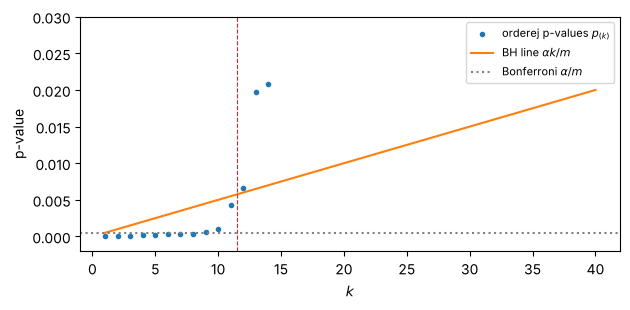

In [3]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
m, alpha, M = 100, 0.05, 4000

def bh(p, alpha=alpha):
    m = len(p); s = np.argsort(p); ok = p[s] <= alpha * np.arange(1, m + 1) / m
    k = (np.nonzero(ok)[0].max() + 1) if ok.any() else 0
    rej = np.zeros(m, bool); rej[s[:k]] = True; return rej

print("All H0 true (m = 100); equicorrelated normal test statistics")
print(" rho | Bonferroni FWER | uncorrected FWER | BH FDR (= FWER)")
for rho in (0.0, 0.3, 0.6, 0.9):
    common = rng.standard_normal((M, 1))
    z = np.sqrt(rho) * common + np.sqrt(1 - rho) * rng.standard_normal((M, m))
    p = 2 * stats.norm.sf(np.abs(z))
    bon = (p <= alpha / m).any(axis=1).mean()
    unc = (p <= alpha).any(axis=1).mean()
    bhf = np.mean([bh(r).any() for r in p])
    print(f" {rho:.1f} |      {bon:.4f}     |      {unc:.4f}      |     {bhf:.4f}")

# Visual interpretation of BH: orderej p-values and the line alpha*k/m
has_eff = np.zeros(m, bool); has_eff[:15] = True
z = rng.standard_normal(m) + 3.0 * has_eff
p = stats.norm.sf(z); s = np.sort(p); k = np.arange(1, m + 1)
rej = bh(p); R = rej.sum()
print(f"Example data: BH rejected {R} hypotheses; real effects: {(rej & has_eff).sum()}, "
      f"false discoveries: {(rej & ~has_eff).sum()}. Bonferroni rejections: {(p <= alpha / m).sum()}.")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(k[:40], s[:40], "o", ms=3, label="orderej p-values $p_{(k)}$")
ax.plot(k[:40], alpha * k[:40] / m, "-", label=r"BH line $\alpha k/m$")
ax.axhline(alpha / m, ls=":", color="gray", label=r"Bonferroni $\alpha/m$")
ax.axvline(R + 0.5, ls="--", color="C3", lw=0.8)
ax.set_xlabel("$k$"); ax.set_ylabel("p-value"); ax.set_ylim(-0.002, 0.03); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("bh_dogrusu.pdf")